In [142]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

#Subimos el archivo de la carpeta data
set_config(transform_output="pandas")

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

titanic =  pd.read_csv(DATA_DIR/"titanic.csv")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [143]:
titanic.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [144]:
titanic.tail(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [145]:
titanic.info()
titanic.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [146]:
print(titanic.duplicated().mean()*100)
for col in ["survived", "pclass", "age","sibsp","parch","fare","embarked","class","who","adult_male","deck","embark_town","alive","alone"]:
    print(titanic[col].value_counts(dropna=False), "\n")

12.008978675645341
survived
0    549
1    342
Name: count, dtype: int64 

pclass
3    491
1    216
2    184
Name: count, dtype: int64 

age
NaN      177
24.00     30
22.00     27
18.00     26
28.00     25
        ... 
24.50      1
0.67       1
0.42       1
34.50      1
74.00      1
Name: count, Length: 89, dtype: int64 

sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64 

parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64 

fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 248, dtype: int64 

embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64 

class
Third     491
First     216
Second    184
Name: count, dtype: int64 

who
man      537
woman    271
child     83
Name: count, dtype: int64 

adult_male
True     537
False    354
Name: count, dtype

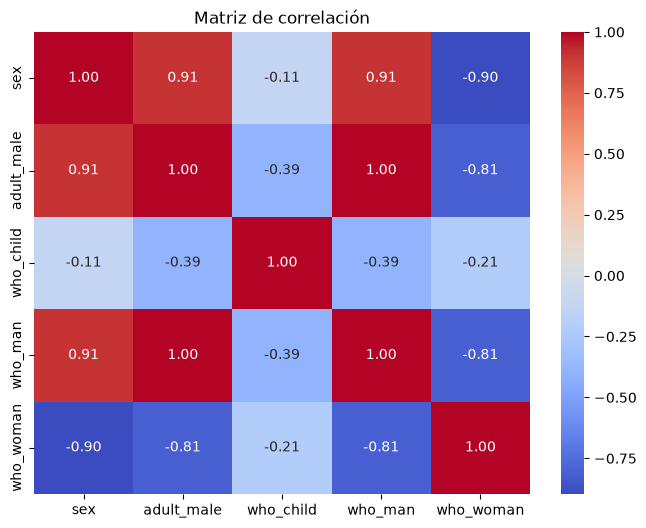

In [147]:
valores = titanic[["sex", "who", "adult_male"]].copy()

valores["sex"] = valores["sex"].map({"male":"1", "female": '0'})

valores["adult_male"] = valores["adult_male"].map({True:"1", False: "0"})

valores = pd.get_dummies(

    valores,

    columns=["who"],

    dtype=int
)

corr = valores.corr()

 

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)

ax.set_title("Matriz de correlación")

plt.show()

## for col in ["survived", "pclass", "age","sibsp","parch","fare","embarked","class","who","adult_male","deck","embark_town","alive","alone"]:

##    print(titanic[col].value_counts(dropna=False), "\n")






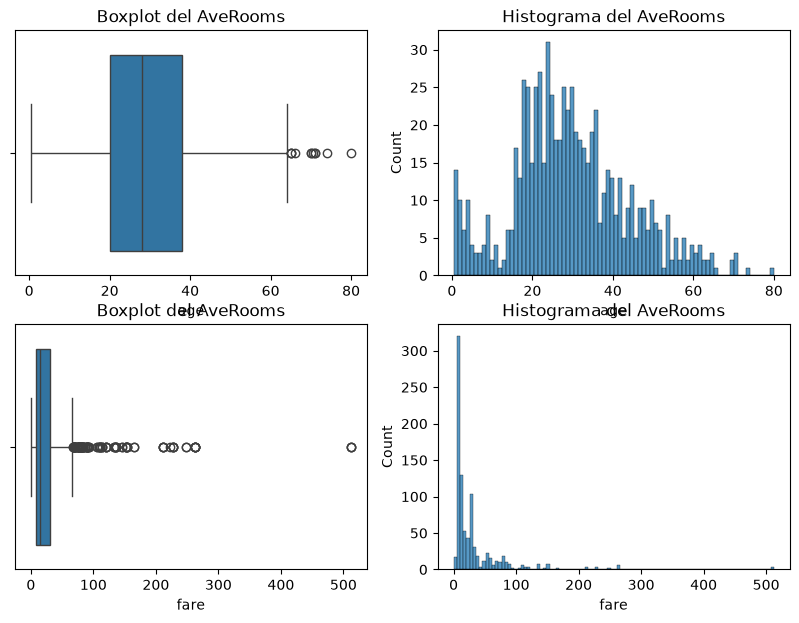

In [148]:


fig1, axes = plt.subplots(2, 2,figsize=(10, 7))
sns.boxplot(x=titanic["age"], ax=axes[0,0])
axes[0,0].set_title("Boxplot del AveRooms")
sns.histplot(x=titanic["age"], bins=80, ax=axes[0,1])
axes[0,1].set_title("Histograma del AveRooms")
sns.boxplot(x=titanic["fare"], ax=axes[1,0])
axes[1,0].set_title("Boxplot del AveRooms")
sns.histplot(x=titanic["fare"], bins=100, ax=axes[1,1])
axes[1,1].set_title("Histograma del AveRooms")
plt.show()


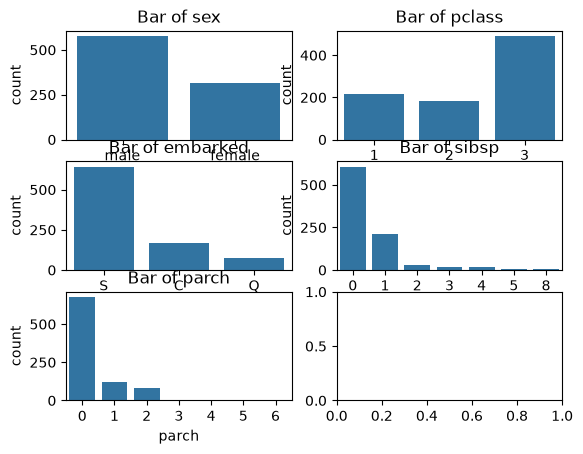

In [149]:


fig, axes = plt.subplots(3, 2)
sns.countplot(data=titanic, x="sex", ax=axes[0,0])
axes[0,0].set_title("Bar of sex")
sns.countplot(data=titanic, x="pclass", ax=axes[0,1])
axes[0,1].set_title("Bar of pclass")
sns.countplot(data=titanic, x="embarked", ax=axes[1,0])
axes[1,0].set_title("Bar of embarked")
sns.countplot(data=titanic, x="sibsp", ax=axes[1,1])
axes[1,1].set_title("Bar of sibsp")
sns.countplot(data=titanic, x="parch", ax=axes[2,0])
axes[2,0].set_title("Bar of parch")
plt.show()

In [150]:
resumen = (titanic.groupby("pclass")["survived"].mean())*100
print(resumen)

pclass
1    62.962963
2    47.282609
3    24.236253
Name: survived, dtype: float64


IndexError: index 3 is out of bounds for axis 0 with size 3

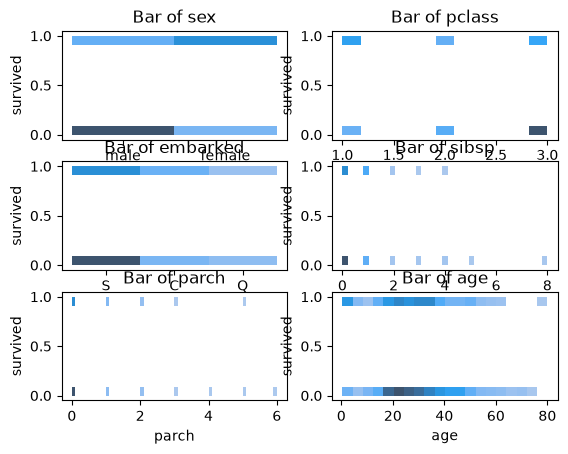